Customer Churn Analysis Project

In [1]:
import pandas as pd 
import matplotlib.pyplot as plt

df=pd.read_csv("Telco_Customer_Churn_Data.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.shape

(7043, 21)

In [3]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [4]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [5]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df['TotalCharges']=pd.to_numeric(df['TotalCharges'],errors='coerce')

In [8]:
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [12]:
df['TotalCharges']=df['TotalCharges'].fillna(df['TotalCharges']).mean()

In [13]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [14]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7.043000e+03
mean,0.162147,32.371149,64.761692,2.283300e+03
std,0.368612,24.559481,30.090047,4.547796e-13
min,0.000000,0.000000,18.250000,2.283300e+03
25%,0.000000,9.000000,35.500000,2.283300e+03
50%,0.000000,29.000000,70.350000,2.283300e+03
75%,0.000000,55.000000,89.850000,2.283300e+03
max,1.000000,72.000000,118.750000,2.283300e+03


In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [18]:
# exploratory data analysis (EDA)
len(df)

7043

In [20]:
#TOTAL CHURN 
df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [25]:
# CHURN % 
round(df['Churn'].value_counts(normalize=True)*100,2)

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

In [26]:
# GENDER DISTRIBUTION
df['gender'].value_counts()

gender
Male      3555
Female    3488
Name: count, dtype: int64

In [27]:
# Contract Distribution
df['Contract'].value_counts()

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

In [30]:
#internet distribution 
df['InternetService'].value_counts()

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

In [31]:
# Payment method
df['PaymentMethod'].value_counts()

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

In [34]:
df['Contract'].unique()

<StringArray>
['Month-to-month', 'One year', 'Two year']
Length: 3, dtype: str

In [35]:
df['Contract'].nunique()

3

In [38]:
round(df.groupby("Contract")['MonthlyCharges'].mean(),2)

Contract
Month-to-month    66.40
One year          65.05
Two year          60.77
Name: MonthlyCharges, dtype: float64

In [42]:
df.sort_values("MonthlyCharges",ascending=False)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
4586,7569-NMZYQ,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),118.75,2283.300441,No
2115,8984-HPEMB,Female,0,No,No,71,Yes,Yes,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Electronic check,118.65,2283.300441,No
4804,5734-EJKXG,Female,0,No,No,61,Yes,Yes,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Electronic check,118.60,2283.300441,No
3894,5989-AXPUC,Female,0,Yes,No,68,Yes,Yes,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,No,Mailed check,118.60,2283.300441,No
5127,8199-ZLLSA,Male,0,No,No,67,Yes,Yes,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Bank transfer (automatic),118.35,2283.300441,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1156,0621-CXBKL,Female,0,No,No,53,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,18.70,2283.300441,No
6906,9945-PSVIP,Female,0,Yes,Yes,25,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,Yes,Mailed check,18.70,2283.300441,No
6652,0827-ITJPH,Male,0,No,No,36,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,Yes,Credit card (automatic),18.55,2283.300441,No
1529,9764-REAFF,Female,0,Yes,No,59,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),18.40,2283.300441,No


In [50]:
# Churned Customers 
df[df['Churn']=="Yes"].shape[0]

1869

In [53]:
# Avg monthly charges of churn customers
round(df[df['Churn']=='Yes']['MonthlyCharges'].mean(),2)

np.float64(74.44)

In [55]:
# Average tenure of churn customers
round(df[df['Churn']=='Yes']['tenure'].mean(),2)

np.float64(17.98)

In [57]:
# Which Contract has highest churn?
pd.crosstab(df["Contract"],df["Churn"])

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


In [59]:
# Which Internet Service loses most customers?
pd.crosstab(df["InternetService"],df["Churn"])

Churn,No,Yes
InternetService,,
DSL,1962,459
Fiber optic,1799,1297
No,1413,113


In [60]:
# Which Payment Method causes highest churn?
pd.crosstab(df['PaymentMethod'],df['Churn'])

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),1286,258
Credit card (automatic),1290,232
Electronic check,1294,1071
Mailed check,1304,308


In [61]:
# Do senior citizens churn more?
pd.crosstab(df['SeniorCitizen'],df['Churn'])

Churn,No,Yes
SeniorCitizen,,
0,4508,1393
1,666,476


In [62]:
# Does Tech Support reduce churn?
pd.crosstab(df['TechSupport'],df['Churn'])

Churn,No,Yes
TechSupport,,
No,2027,1446
No internet service,1413,113
Yes,1734,310


In [63]:
# Does Online Security reduce churn?
pd.crosstab(df['OnlineSecurity'],df['Churn'])

Churn,No,Yes
OnlineSecurity,,
No,2037,1461
No internet service,1413,113
Yes,1724,295


In [64]:
# Average Monthly Charges by Contract
round(df.groupby("Contract")["MonthlyCharges"].mean(),2)

Contract
Month-to-month    66.40
One year          65.05
Two year          60.77
Name: MonthlyCharges, dtype: float64

<Axes: xlabel='Churn'>

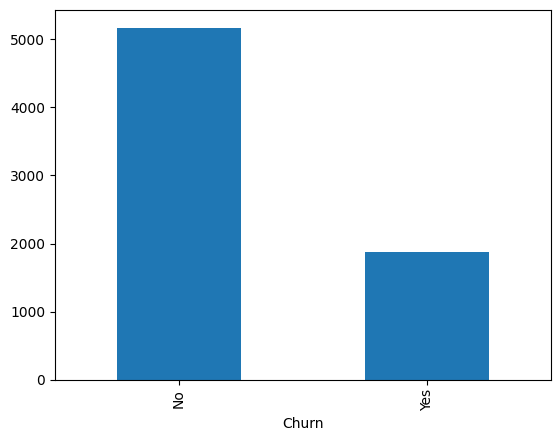

In [65]:
# Churn Count
df['Churn'].value_counts().plot(kind='bar')

Text(0.5, 1.0, 'gender count')

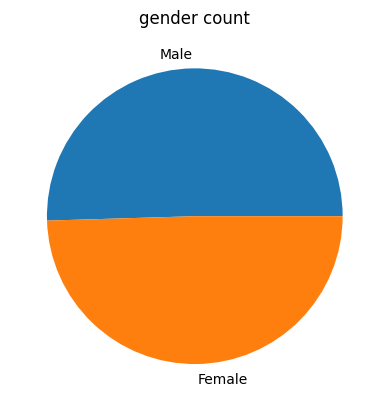

In [68]:
# Gender
df['gender'].value_counts().plot(kind='pie')
plt.title("gender count")

<Axes: ylabel='Frequency'>

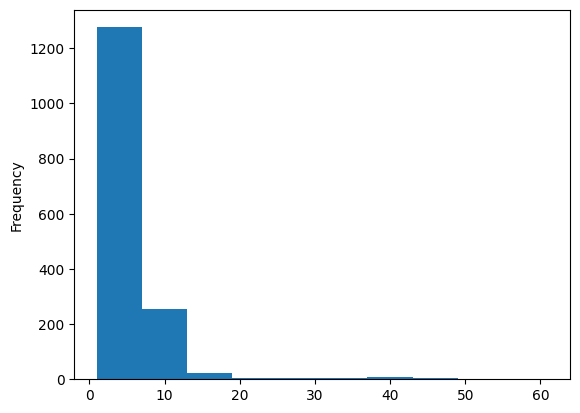

In [75]:
df['MonthlyCharges'].value_counts().plot(kind='hist')

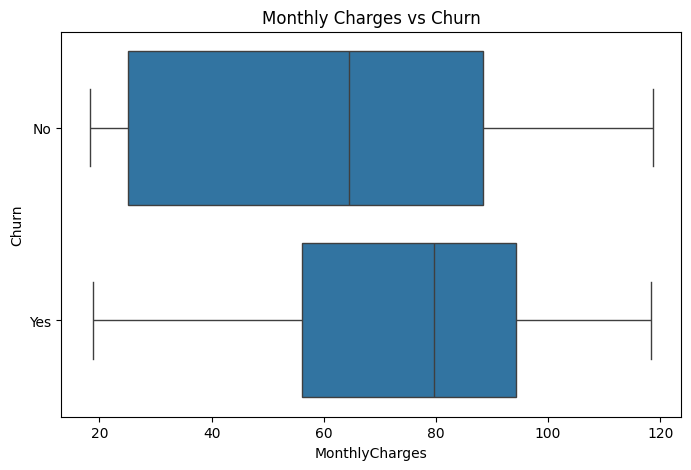

In [ ]:
import seaborn as sns
plt.figure(figsize=(8,5))
sns.boxplot(data=df,x='MonthlyCharges',y='Churn')
plt.title("Monthly Charges vs Churn")
plt.show()

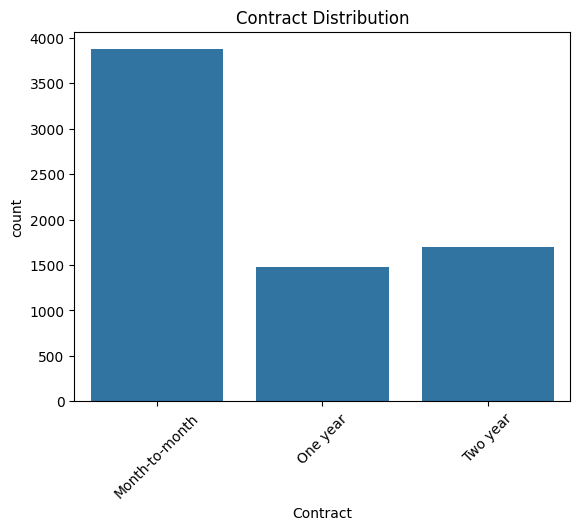

In [81]:
# Count Plot → Contract
sns.countplot(data=df,x='Contract')
plt.title('Contract Distribution')
plt.xticks(rotation=45)
plt.show()

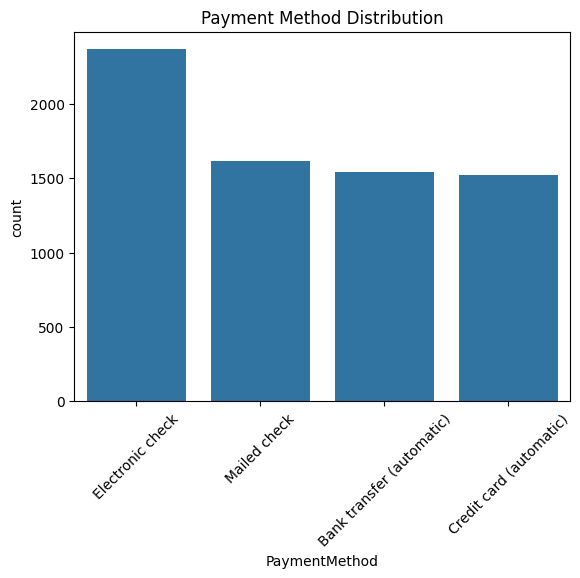

In [82]:
# Count Plot → Payment Method
sns.countplot(data=df,x='PaymentMethod')
plt.title('Payment Method Distribution')
plt.xticks(rotation=45)
plt.show()

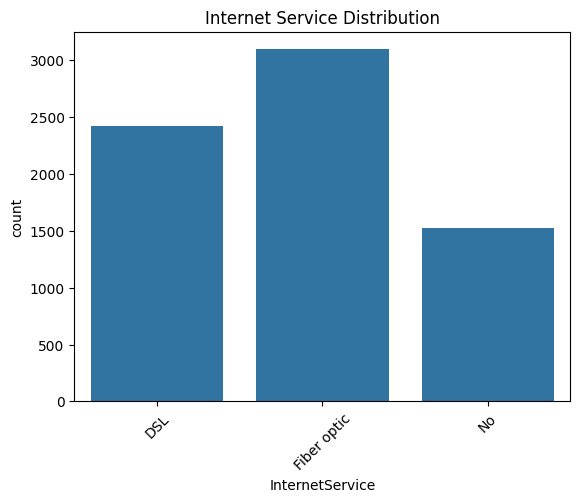

In [83]:
# Count Plot → Internet Service
# Count Plot → Payment Method
sns.countplot(data=df,x='InternetService')
plt.title('Internet Service Distribution')
plt.xticks(rotation=45)
plt.show()

In [90]:
df.to_csv("Cleaned_Telecom_Data")